## Section 1: Setup

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from pathlib import Path
from IPython.display import display, Image

DATA_DIR = Path('system_result')

models = {
    'model3': 'Resnet152',
    'model4': 'Bert',
}

default_batch = {'Resnet152': 4, 'Bert': 4}

# Load all data
node_stats = {}
act_lifetimes = {}
peak_summaries = {}

for folder, name in models.items():
    node_stats[name] = pd.read_csv(DATA_DIR / folder / 'node_stats.csv')
    act_lifetimes[name] = pd.read_csv(DATA_DIR / folder / 'activation_lifetimes.csv')
    ps = pd.read_csv(DATA_DIR / folder / 'peak_memory_summary.csv')
    peak_summaries[name] = {k: pd.to_numeric(v, errors='coerce') for k, v in zip(ps['category'], ps['bytes'])}

batchsize_df = pd.read_csv(DATA_DIR / 'peak_memory_vs_batchsize.csv')

def extract_op_type(name):
    return re.sub(r'_\d+$', '', name)


## Section 2: Overall Iteration Summary

In [10]:
for name in models.values():
    df = node_stats[name]
    ps = peak_summaries[name]

    # Time by region
    time_by_region = df.groupby('region')['avg_ms'].sum()
    total_time = df['avg_ms'].sum()

    # Node counts
    total_nodes = len(df)
    n_activations = len(act_lifetimes[name])

    summary = pd.DataFrame({
        'Metric': [
            'Total Nodes',
            'Activation Nodes',
            'Total Iteration Time (ms)',
            'Forward Time (ms)',
            'Backward Time (ms)',
            'Optimizer Time (ms)',
            'Peak Memory (MB)',
            'Peak Step (node index)',
            'Peak Node',
        ],
        'Value': [
            total_nodes,
            n_activations,
            f'{total_time:.2f}',
            f"{time_by_region.get('forward', 0):.2f}",
            f"{time_by_region.get('backward', 0):.2f}",
            f"{time_by_region.get('optimizer', 0):.2f}",
            f"{ps['total'] / (1024**2):.2f}",
            int(ps['peak_step']),
            ps.get('peak_node', 'N/A'),
        ]
    })

    print(f'\n=== {name} (batch_size={default_batch[name]}) ===')
    display(summary.style.hide(axis='index'))


=== Resnet152 (batch_size=4) ===


Metric,Value
Total Nodes,8682
Activation Nodes,778
Total Iteration Time (ms),448.29
Forward Time (ms),151.94
Backward Time (ms),138.79
Optimizer Time (ms),156.97
Peak Memory (MB),2296.18
Peak Step (node index),6811
Peak Node,nan



=== Bert (batch_size=4) ===


Metric,Value
Total Nodes,4523
Activation Nodes,362
Total Iteration Time (ms),258.55
Forward Time (ms),72.68
Backward Time (ms),120.85
Optimizer Time (ms),64.68
Peak Memory (MB),4176.48
Peak Step (node index),3716
Peak Node,nan


## Section 3: Per-Operator Compute and Memory Profiling

In [11]:
# Forward vs Backward vs Optimizer time split
for name in models.values():
    df = node_stats[name]
    time_by_region = df.groupby('region')['avg_ms'].sum()
    total = time_by_region.sum()

    split = pd.DataFrame({
        'Region': time_by_region.index,
        'Time (ms)': [f'{v:.2f}' for v in time_by_region.values],
        '% of Total': [f'{v/total*100:.1f}%' for v in time_by_region.values],
    })

    print(f'\n=== {name}: Time Split by Region ===')
    display(split.style.hide(axis='index'))

# Memory delta by region
for name in models.values():
    df = node_stats[name]
    mem_by_region = df.groupby('region')['avg_mem_delta'].sum()

    split = pd.DataFrame({
        'Region': mem_by_region.index,
        'Net Memory Delta (MB)': [f'{v/(1024**2):.2f}' for v in mem_by_region.values],
    })

    print(f'\n=== {name}: Net Memory Change by Region ===')
    display(split.style.hide(axis='index'))


=== Resnet152: Time Split by Region ===


Region,Time (ms),% of Total
backward,138.79,31.0%
forward,151.94,33.9%
optimizer,156.97,35.0%
other,0.59,0.1%



=== Bert: Time Split by Region ===


Region,Time (ms),% of Total
backward,120.85,46.7%
forward,72.68,28.1%
optimizer,64.68,25.0%
other,0.34,0.1%



=== Resnet152: Net Memory Change by Region ===


Region,Net Memory Delta (MB)
backward,1493.00
forward,707.21
optimizer,937.36
other,0.00



=== Bert: Net Memory Change by Region ===


Region,Net Memory Delta (MB)
backward,1275.40
forward,428.75
optimizer,1672.91
other,0.00


## Section 4: Memory Timeline Over Execution

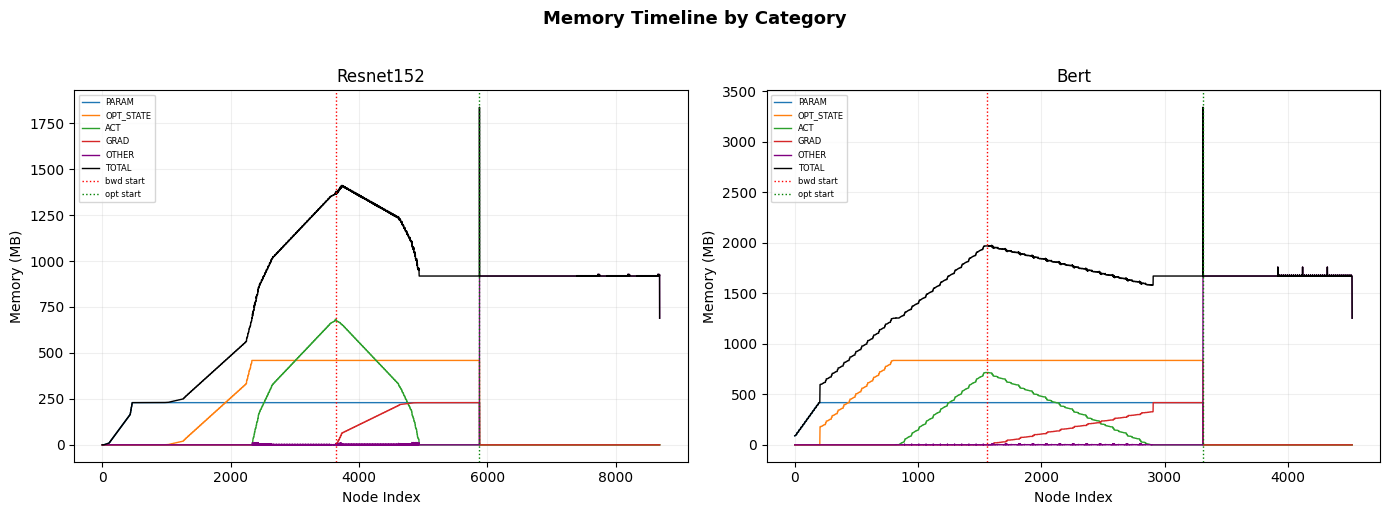

In [12]:
# Reconstruct liveness simulation — track ALL nodes from creation to last use
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, name in zip(axes, models.values()):
    ns = node_stats[name]
    al = act_lifetimes[name]
    num_nodes = len(ns)

    # Find optimizer node index (the _fused_adam node)
    opt_rows = ns[ns['name'].str.contains('fused_adam', na=False)]
    opt_idx = int(opt_rows['idx'].iloc[0]) if len(opt_rows) > 0 else num_nodes - 1

    # Find sep and sep_backward indices
    sep_rows = ns[ns['name'] == 'sep']
    sep_bwd_rows = ns[ns['name'] == 'sep_backward']
    sep_idx = int(sep_rows['idx'].iloc[0]) if len(sep_rows) > 0 else None
    sep_bwd_idx = int(sep_bwd_rows['idx'].iloc[0]) if len(sep_bwd_rows) > 0 else None

    # Category arrays
    params = np.zeros(num_nodes, dtype=np.float64)
    opt_states = np.zeros(num_nodes, dtype=np.float64)
    activations = np.zeros(num_nodes, dtype=np.float64)
    grads = np.zeros(num_nodes, dtype=np.float64)
    other = np.zeros(num_nodes, dtype=np.float64)

    for _, row in ns.iterrows():
        idx = int(row['idx'])
        size = row['output_bytes']
        if size == 0:
            continue
        ntype = row['type']
        region = row['region']

        if ntype == 'PARAM':
            # Params: alive from placeholder to optimizer
            for i in range(idx, opt_idx + 1):
                params[i] += size
        elif ntype == 'OPT_STATE':
            # Opt states: alive from placeholder to optimizer
            for i in range(idx, opt_idx + 1):
                opt_states[i] += size
        elif ntype == 'GRAD':
            # Grads: alive from placeholder to optimizer
            for i in range(idx, opt_idx + 1):
                grads[i] += size
        elif ntype == 'ACT':
            pass  # handled below with activation_lifetimes
        else:
            # OTHER nodes: alive for just this one step (transient)
            if 'fused_adam' in row['name']:
                # _fused_adam output tuple stays alive until the last getitem unpacks it.
                # After opt_idx, PARAM/OPT_STATE/GRAD tracking ends, so this covers
                # the memory that persists through the getitem unpacking region.
                opt_nodes = ns[(ns['region'] == 'optimizer') & (ns['idx'] > idx)]
                if len(opt_nodes) > 0:
                    last_user = int(opt_nodes['idx'].max())
                else:
                    last_user = idx
                for i in range(idx, last_user + 1):
                    other[i] += size
            elif region == 'optimizer' and 'getitem' in row['name']:
                # getitem just indexes into _fused_adam's tuple — no new allocation.
                # Skip to avoid double-counting with _fused_adam output above.
                continue
            else:
                other[idx] += size

    # Activations: use activation_lifetimes for accurate lifetime
    for _, row in al.iterrows():
        size = row['size_bytes'] if row['size_bytes'] > 0 else 0
        start = int(row['producer_idx'])
        end = min(int(row['first_bwd_use']) + 1, num_nodes)
        activations[start:end] += size

    # Convert to MB
    params_mb = params / (1024**2)
    opt_states_mb = opt_states / (1024**2)
    activations_mb = activations / (1024**2)
    grads_mb = grads / (1024**2)
    other_mb = other / (1024**2)
    total_mb = params_mb + opt_states_mb + activations_mb + grads_mb + other_mb

    x = np.arange(num_nodes)
    ax.plot(x, params_mb, label='PARAM', linewidth=1)
    ax.plot(x, opt_states_mb, label='OPT_STATE', linewidth=1)
    ax.plot(x, activations_mb, label='ACT', linewidth=1)
    ax.plot(x, grads_mb, label='GRAD', linewidth=1)
    ax.plot(x, other_mb, label='OTHER', linewidth=1, color='purple')
    ax.plot(x, total_mb, label='TOTAL', linewidth=1, color='black')

    # Mark region boundaries
    if sep_bwd_idx is not None:
        ax.axvline(x=sep_bwd_idx, color='red', linestyle=':', linewidth=1.0, label='bwd start')
    ax.axvline(x=opt_idx, color='green', linestyle=':', linewidth=1.0, label='opt start')

    # Mark fwd+bwd peak
    fwd_bwd_peak_idx = np.argmax(total_mb[:opt_idx])

    # Annotate overall peak and fwd+bwd peak
    overall_peak_idx = np.argmax(total_mb)

    ax.set_xlabel('Node Index')
    ax.set_ylabel('Memory (MB)')
    ax.set_title(f'{name}')
    ax.legend(fontsize=6, loc='upper left')
    ax.grid(True, alpha=0.2)

fig.suptitle('Memory Timeline by Category', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('memory_timeline_individual.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
# Activation lifetime examples
for name in models.values():
    df = act_lifetimes[name].copy()
    df['size_mb'] = df['size_bytes'] / (1024**2)

    top = df.nlargest(15, 'size_bytes')[['name', 'producer_idx', 'last_fwd_use', 'first_bwd_use', 'idle_steps', 'size_mb']].copy()
    top.columns = ['Name', 'Created', 'Last Fwd', '1st Bwd', 'Idle Steps', 'MB']
    top['MB'] = top['MB'].map('{:.2f}'.format)

    print(f'\n=== {name}: Top 15 Activations by Size ===')
    display(top.reset_index(drop=True).style.hide(axis='index'))


=== Resnet152: Top 15 Activations by Size ===


Name,Created,Last Fwd,1st Bwd,Idle Steps,MB
relu__3,2379,2403,4896,2493,12.25
convolution,2337,2339,4934,2595,12.25
relu__6,2404,2428,4871,2443,12.25
convolution_3,2364,2366,4908,2542,12.25
relu__9,2429,2453,4823,2370,12.25
relu_,2344,2345,4932,2587,12.25
convolution_4,2371,2373,4901,2528,12.25
convolution_7,2396,2398,4876,2478,12.25
convolution_10,2421,2423,4851,2428,12.25
t,3628,3629,3643,14,7.81



=== Bert: Top 15 Activations by Size ===


Name,Created,Last Fwd,1st Bwd,Idle Steps,MB
t_40,1237,1238,2154,916,9.00
t_52,1353,1354,1936,582,9.00
t_47,1300,1301,2034,733,9.00
t_10,947,948,2699,1751,9.00
t_22,1063,1064,2481,1417,9.00
t_71,1532,1533,1598,65,9.00
t_34,1179,1180,2263,1083,9.00
t_46,1295,1296,2045,749,9.00
t_17,1010,1011,2579,1568,9.00
t_58,1411,1412,1827,415,9.00


## Section 6: Peak Memory Breakdown

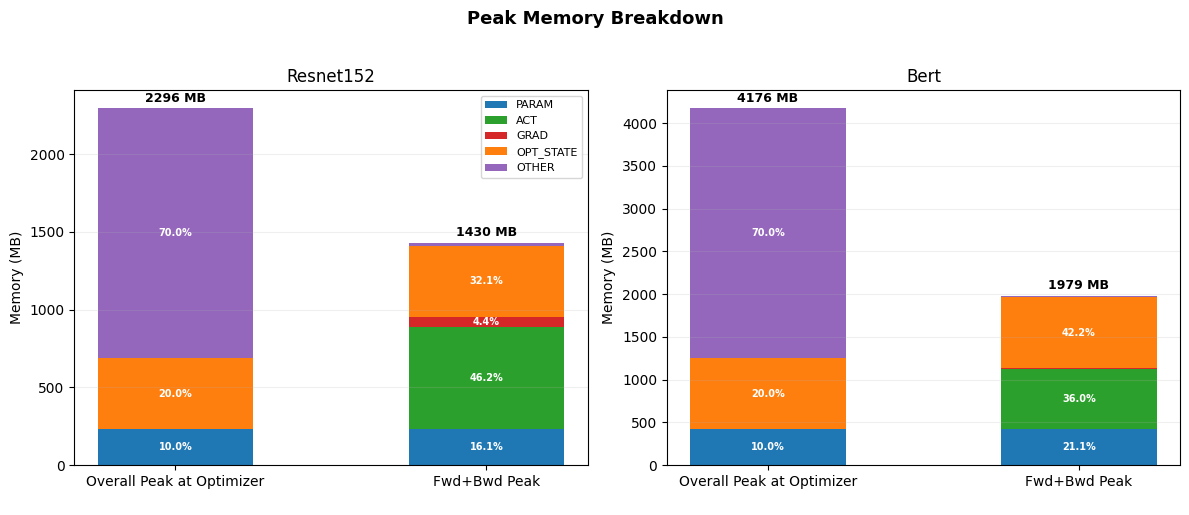

In [14]:
# Peak memory breakdown
categories = ['params', 'activations', 'grads', 'opt_states', 'other']
labels = ['PARAM', 'ACT', 'GRAD', 'OPT_STATE', 'OTHER']
colors = ['#1f77b4', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, models.values()):
    ps = peak_summaries[name]

    # Overall peak (at optimizer)
    overall_sizes = [ps.get(c, 0) / (1024**2) for c in categories]
    overall_total = sum(overall_sizes)

    # Fwd+Bwd peak
    fwd_bwd_cats = ['fwd_bwd_' + c for c in categories]
    fwd_bwd_sizes = [ps.get(c, 0) / (1024**2) for c in fwd_bwd_cats]
    fwd_bwd_total = sum(fwd_bwd_sizes)

    x = np.arange(2)
    width = 0.5
    bottom_overall = 0.0
    bottom_fwd_bwd = 0.0

    for i, (label, color) in enumerate(zip(labels, colors)):
        bar1 = ax.bar(x[0], overall_sizes[i], width, bottom=bottom_overall, color=color,
                       label=label if name == list(models.values())[0] else None)
        bar2 = ax.bar(x[1], fwd_bwd_sizes[i], width, bottom=bottom_fwd_bwd, color=color)

        # Add percentage label inside segment if > 3%
        pct_overall = overall_sizes[i] / overall_total * 100 if overall_total > 0 else 0
        if pct_overall > 3:
            ax.text(x[0], bottom_overall + overall_sizes[i] / 2,
                    f'{pct_overall:.1f}%', ha='center', va='center', fontsize=7, fontweight='bold', color='white')

        pct_fwd_bwd = fwd_bwd_sizes[i] / fwd_bwd_total * 100 if fwd_bwd_total > 0 else 0
        if pct_fwd_bwd > 3:
            ax.text(x[1], bottom_fwd_bwd + fwd_bwd_sizes[i] / 2,
                    f'{pct_fwd_bwd:.1f}%', ha='center', va='center', fontsize=7, fontweight='bold', color='white')

        bottom_overall += overall_sizes[i]
        bottom_fwd_bwd += fwd_bwd_sizes[i]

    ax.set_xticks(x)
    ax.set_xticklabels(['Overall Peak at Optimizer\n', 'Fwd+Bwd Peak\n'])
    ax.set_ylabel('Memory (MB)')
    ax.set_title(f'{name}')
    ax.text(x[0], overall_total + max(overall_total, fwd_bwd_total)*0.01, f'{overall_total:.0f} MB', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.text(x[1], fwd_bwd_total + max(overall_total, fwd_bwd_total)*0.01, f'{fwd_bwd_total:.0f} MB', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.grid(True, alpha=0.2, axis='y')

axes[0].legend(fontsize=8, loc='upper right')
fig.suptitle('Peak Memory Breakdown', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('peak_memory_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 7: Peak Memory vs Mini-Batch Size

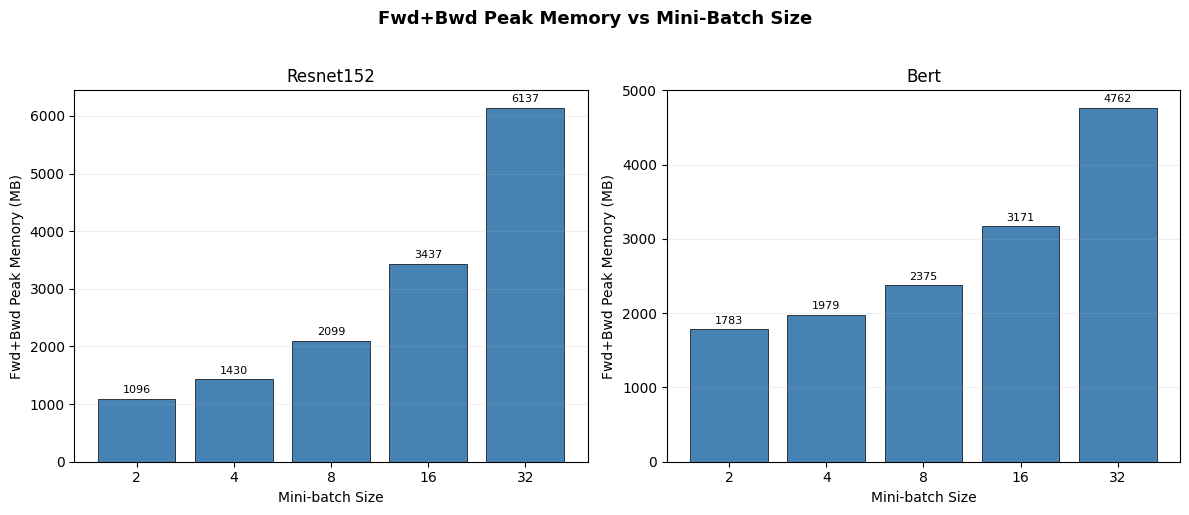

In [15]:
# Peak memory vs batch size bar chart
focus_models = ['Resnet152', 'Bert']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model_name in zip(axes, focus_models):
    mdf = batchsize_df[batchsize_df['model'] == model_name].sort_values('batch_size')
    if len(mdf) == 0:
        ax.set_title(f'{model_name} — No data')
        continue
    x = [str(bs) for bs in mdf['batch_size']]
    y = mdf['peak_memory_MB'].values
    bars = ax.bar(x, y, color='steelblue', edgecolor='black', linewidth=0.5)
    # Add value labels on bars
    for bar, val in zip(bars, y):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(y)*0.01,
                f'{val:.0f}', ha='center', va='bottom', fontsize=8)
    ax.set_xlabel('Mini-batch Size')
    ax.set_ylabel('Fwd+Bwd Peak Memory (MB)')
    ax.set_title(f'{model_name}')
    ax.grid(True, alpha=0.2, axis='y')

fig.suptitle('Fwd+Bwd Peak Memory vs Mini-Batch Size', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('peak_memory_vs_batchsize_bar.png', dpi=150, bbox_inches='tight')
plt.show()